In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset and safely handle any malformed lines
df = pd.read_csv('data.csv', index_col=0, on_bad_lines='skip')

# Preview the first 5 rows
df.head()

/tmp/ipykernel_3510/1344281557.py:6: DtypeWarning: Columns (1325,4222) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('data.csv', index_col=0, on_bad_lines='skip')


,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,gene_9,...,gene_20521,gene_20522,gene_20523,gene_20524,gene_20525,gene_20526,gene_20527,gene_20528,gene_20529,gene_20530
sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871,0.0,0.0,...,4.926711,8.210257,9.723516,7.220030,9.119813,12.003135,9.650743,8.921326,5.286759,0.0
sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000,0.0,0.0,...,4.593372,7.323865,9.740931,6.256586,8.381612,12.674552,10.517059,9.397854,2.094168,0.0
sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595,0.0,0.0,...,5.125213,8.127123,10.908640,5.401607,9.911597,9.045255,9.788359,10.090470,1.683023,0.0
sample_90,0.0,1.950431,4.027322,6.427229,9.617234,0.0,7.075297,1.494211,0.0,0.0,...,5.419300,8.458189,9.936345,7.319148,9.692033,11.712239,9.836660,9.508662,6.482708,0.0
sample_91,0.0,3.801966,3.459130,5.997184,9.710472,0.0,8.905616,0.554147,0.0,0.0,...,5.477337,8.329877,9.821407,5.801886,9.755719,11.027975,9.899875,9.385343,4.401617,0.0


In [7]:
# Select only numeric columns before calculating the mean expression
numeric_df = df.select_dtypes(include=['number'])

# Calculate mean expression across all numeric sample columns for each gene row
numeric_df['mean_expression'] = numeric_df.mean(axis=1)

# Sort in descending order and select the top 10 highly expressed genes
top10 = numeric_df['mean_expression'].sort_values(ascending=False).head(10)

print("Top 10 Highly Expressed Genes:")
print(top10)

Top 10 Highly Expressed Genes:
sample_40     7.269806
sample_798    7.074227
sample_44     6.878659
sample_190    6.878139
sample_218    6.849979
sample_85     6.843369
sample_419    6.829509
sample_318    6.783621
sample_675    6.773747
sample_37     6.770787
Name: mean_expression, dtype: float64


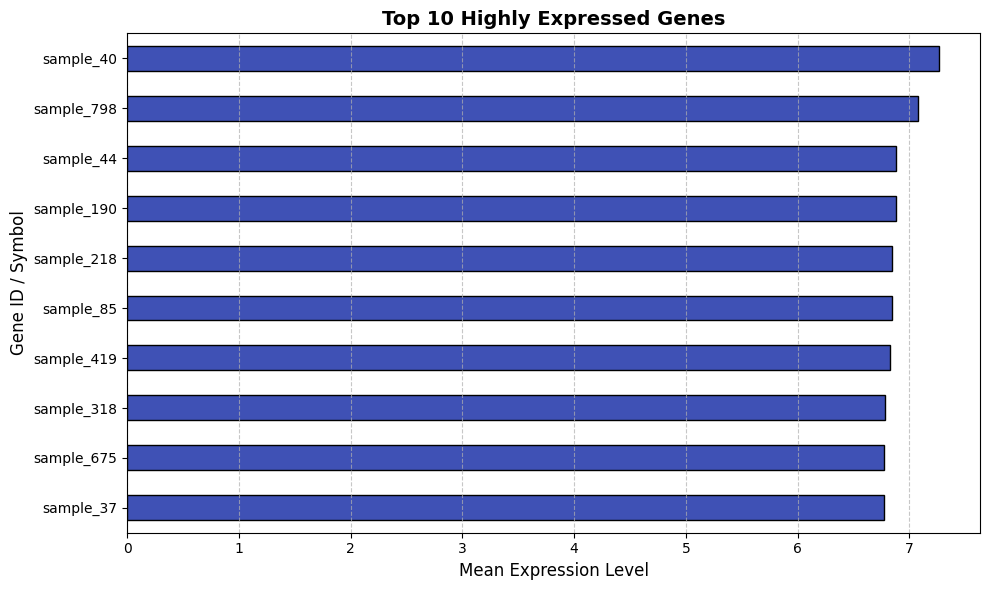

In [8]:
# Create a horizontal bar chart
plt.figure(figsize=(10, 6))
top10.plot(kind='barh', color='#3f51b5', edgecolor='black')

plt.title('Top 10 Highly Expressed Genes', fontsize=14, fontweight='bold')
plt.xlabel('Mean Expression Level', fontsize=12)
plt.ylabel('Gene ID / Symbol', fontsize=12)
plt.gca().invert_yaxis()  # Puts the highest ranked gene at the top
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('top_genes.png')
plt.show()

### Gene Expression Analysis Summary
1. **What is gene expression?** Gene expression is the cellular process by which genetic instructions (DNA) are transcribed into RNA and translated into functional proteins to drive cellular activity.
2. **What do high expression values mean?** High expression values reflect high transcript abundance or read counts in the sample, indicating that the gene is actively transcribed and heavily utilized by the cell.
3. **Top-Ranked Gene (#1) Significance:** The top-ranked gene shows the highest average expression level across all samples in the dataset, commonly representing structural elements, metabolic enzymes, or highly active housekeeping genes essential for cellular survival.